# Demo: missing-aware multi-domain fault diagnosis

This notebook runs the trained pipeline on 210 validation windows: 10 windows per class and operating domain for the six known classes (C0–C5), plus 10 per domain of a fault type that was never used for training (U).

1. **Masked reconstruction.** 60% of the 16-sample patches of each window are removed at random and filled by the frozen index-aware MAE.
2. **Diagnosis with missing input.** A contiguous segment covering 0, 5, 10 or 15% of each window is removed and filled by the MAE; the completed windows are diagnosed, and each one is accepted, sent for review or flagged as out-of-distribution (OOD).

Run all cells in order from the repository root.

In [1]:
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from src.mae import load_configured_mae
from src.completion import mae_complete
from src.diagnosis import load_diagnosis_model

t_start = time.perf_counter()
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.14.1+cu130 | device: cpu


## Data and trained models

In [2]:
x = np.load("data/x_demo.npy")   # (n, 4096) vibration windows
y = np.load("data/y_demo.npy")   # class: 0-5 known, 6 unknown
d = np.load("data/d_demo.npy")   # operating domain: 0-2
known, unknown = y < 6, y == 6

mae, _ = load_configured_mae("weights/rope_mae_pretrained.pth", device)
model = load_diagnosis_model("weights/fault_diagnosis_uq_augmented.pth", device)
P, L = mae.patch_size, mae.num_patches   # 16 samples per patch, 256 patches per window


def remove_and_complete(patch_mask):
    # delete the masked patches (NaN) and fill them with the frozen MAE
    sample_mask = np.repeat(patch_mask, P, axis=1)
    observed = np.where(sample_mask, np.nan, x).astype(np.float32)
    return mae_complete(mae, observed, patch_mask), sample_mask


print(f"{len(x)} windows x {x.shape[1]} samples: {known.sum()} known, {unknown.sum()} unknown")
pd.crosstab(pd.Series(np.where(known, "C" + y.astype(str), "U"), name="class"),
            pd.Series("D" + d.astype(str), name="domain"))

210 windows x 4096 samples: 180 known, 30 unknown


domain,D0,D1,D2
class,,,
C0,10,10,10
C1,10,10,10
C2,10,10,10
C3,10,10,10
C4,10,10,10
C5,10,10,10
U,10,10,10


## 1. Masked reconstruction

Removed samples are set to NaN. Only the visible patches enter the MAE encoder, each with its original position index; the decoder predicts the removed patches, and observed samples are returned unchanged.

Removed: 60.2% of each window
Masked RMSE: 0.0787 (mean over 180 known windows)


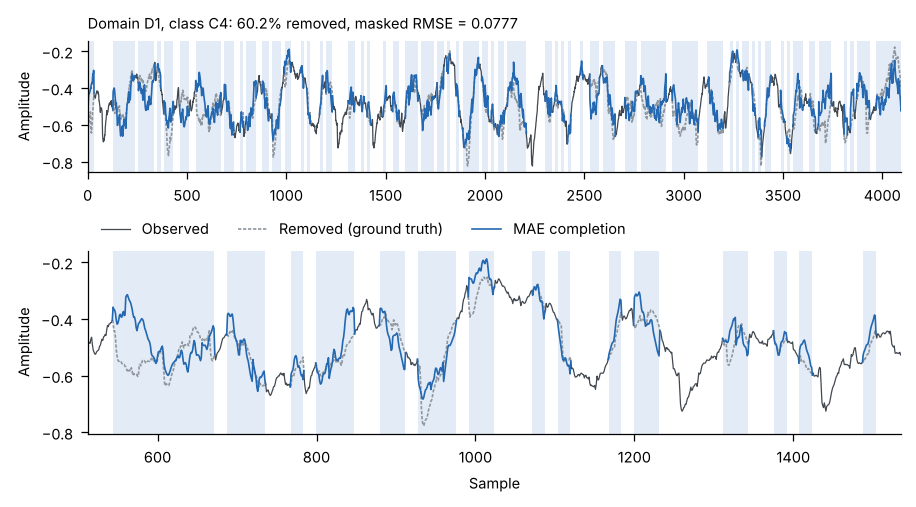

In [3]:
rng = np.random.default_rng(2026)
n_masked = L - int(L * (1 - 0.60))                              # 154 of 256 patches
patch_mask = rng.random((len(x), L)).argsort(1).argsort(1) < n_masked
completed, missing = remove_and_complete(patch_mask)

rmse = np.sqrt(((completed - x) ** 2 * missing).sum(1) / missing.sum(1))   # error on removed samples only
print(f"Removed: {missing[0].mean():.1%} of each window")
print(f"Masked RMSE: {rmse[known].mean():.4f} (mean over {known.sum()} known windows)")

# example: the known window with the median masked RMSE
ids = np.flatnonzero(known)
i = ids[np.argsort(rmse[ids])[len(ids) // 2]]


def spans(mask):
    edge = np.diff(np.r_[0, mask.astype(int), 0])
    return zip(np.flatnonzero(edge == 1), np.flatnonzero(edge == -1))


plt.rcParams.update({"figure.dpi": 150, "font.size": 7, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6})
m = missing[i]
near = m | np.r_[m[1:], False] | np.r_[False, m[:-1]]   # join the filled segments to their neighbours
t = np.arange(x.shape[1])
fig, axes = plt.subplots(2, 1, figsize=(7.0, 3.4), gridspec_kw=dict(height_ratios=[1, 1.4], hspace=0.5))
for ax, (lo, hi) in zip(axes, [(0, x.shape[1]), (512, 1536)]):
    for a, b in spans(m[lo:hi]):
        ax.axvspan(lo + a - 0.5, lo + b - 0.5, color="#E3ECF6", lw=0)
    s = slice(lo, hi)
    ax.plot(t[s], np.where(m, np.nan, x[i])[s], color="#424850", lw=0.6, label="Observed")
    ax.plot(t[s], np.where(near, x[i], np.nan)[s], color="#8F969E", lw=0.8, ls=(0, (2, 1)), label="Removed (ground truth)")
    ax.plot(t[s], np.where(near, completed[i], np.nan)[s], color="#2468B2", lw=0.8, label="MAE completion")
    ax.set_xlim(lo, hi)
    ax.set_ylabel("Amplitude")
axes[0].set_title(f"Domain D{d[i]}, class C{y[i]}: {m.mean():.1%} removed, masked RMSE = {rmse[i]:.4f}",
                  loc="left", fontsize=7)
axes[1].set_xlabel("Sample")
axes[1].legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
plt.show()

## 2. Diagnosis with missing input

A contiguous segment covering 0, 5, 10 or 15% of each window is removed at a random position (three positions per window; the same positions are used for all rates, so the segments are nested) and filled by the MAE. Each completed window is passed to the dual-branch classifier (frozen MAE features + Welch log-PSD, five fusion heads). The decision layer then either accepts the predicted class, sends the window for review (high ensemble risk) or flags it as an OOD candidate (high novelty score). The thresholds were calibrated on known training windows only.

In [4]:
REPEATS = 3                                                    # random segment positions per rate
rng = np.random.default_rng(2026)
starts = rng.integers(0, L - round(0.15 * L) + 1, (REPEATS, len(x)))   # first missing patch of each window
idx = np.arange(L)


def summarize(out):
    dec = out["decision"]                                      # class 0-5 = accepted, -2 = review, -1 = OOD
    correct = out["predicted_class"] == y
    return {
        "known: accuracy": correct[known].mean(),
        "known: accepted": (dec[known] >= 0).mean(),
        "known: review": (dec[known] == -2).mean(),
        "known: OOD": (dec[known] == -1).mean(),
        "accepted accuracy": correct[known & (dec >= 0)].mean(),
        "unknown: accepted": (dec[unknown] >= 0).mean(),
        "unknown: review": (dec[unknown] == -2).mean(),
        "unknown: OOD": (dec[unknown] == -1).mean(),
    }


rows, outputs = {}, {}
for rate in (0.0, 0.05, 0.10, 0.15):
    n_missing = round(rate * L)                                # 0, 13, 26 or 38 patches
    runs = []
    for r, start in enumerate(starts if n_missing else starts[:1]):
        patch_mask = (idx >= start[:, None]) & (idx < start[:, None] + n_missing)
        out = model.predict(remove_and_complete(patch_mask)[0] if n_missing else x, d)
        if r == 0:
            outputs[rate] = out                                # first mask, shown per window below
        runs.append(summarize(out))
    rows[f"{100 * n_missing / L:.2f}"] = pd.DataFrame(runs).mean()

print(f"% of known ({known.sum()}) or unknown ({unknown.sum()}) windows; mean over {REPEATS} masks")
table = 100 * pd.DataFrame(rows).T
table.index.name = "missing input (%)"
table.round(1)

% of known (180) or unknown (30) windows; mean over 3 masks


,known: accuracy,known: accepted,known: review,known: OOD,accepted accuracy,unknown: accepted,unknown: review,unknown: OOD
missing input (%),,,,,,,,
0.00,100.0,97.2,0.0,2.8,100.0,0.0,0.0,100.0
5.08,100.0,78.7,0.0,21.3,100.0,0.0,0.0,100.0
10.16,99.6,96.7,0.0,3.3,99.6,0.0,0.0,100.0
14.84,99.8,98.9,0.0,1.1,99.8,0.0,0.0,100.0


Per-window output at 15% missing input (first mask) for one known and one unknown window from each domain:

In [5]:
out = outputs[0.15]
ids = [np.flatnonzero(c & (d == k))[0] for c in (known, unknown) for k in range(3)]
label = {-1: "OOD", -2: "review"}
pd.DataFrame({
    "domain": d[ids],
    "true class": [f"C{v}" if v < 6 else "U" for v in y[ids]],
    "predicted": [f"C{v}" for v in out["predicted_class"][ids]],
    "decision": [label.get(v, "accept") for v in out["decision"][ids]],
    "novelty - threshold": out["ood_excess"][ids].round(2),
    "risk - threshold": out["review_excess"][ids].round(2),
}, index=pd.Index(ids, name="window"))

,domain,true class,predicted,decision,novelty - threshold,risk - threshold
window,,,,,,
0,0,C0,C0,accept,-1.43,-16.00
70,1,C0,C0,accept,-2.43,-17.67
140,2,C0,C0,accept,-1.41,-10.80
60,0,U,C5,OOD,4.10,-8.55
130,1,U,C4,OOD,2.27,-9.65
200,2,U,C5,OOD,2.54,-12.44


In [6]:
print(f"Total run time: {time.perf_counter() - t_start:.0f} s")

Total run time: 68 s
